# EcoCore — Accuracy-Focused LinuxONE Decision Dashboard

This version fixes two accuracy problems in the previous dashboard:

1. **Risk display precision**: live risk is shown with two decimal places, so a small
   probability is not misleadingly rendered as `0.00%`.
2. **What-if decision logic**: projected CPU/memory trends are preserved when scoring
   scenarios. If every available action still leaves critical residual risk, the engine
   returns **Escalate / investigate** instead of incorrectly saying **No action**.

### Important accuracy statement
The ML model is trained on **synthetic future-pressure labels**, exactly as in the
Member 2 notebook. Its accuracy/precision/recall/F1 therefore measure the synthetic
benchmark, not real production incidents. Real-world accuracy requires a labeled
LinuxONE history. This notebook never presents synthetic values as live hardware.

In [31]:
import os, sys, importlib
from datetime import datetime
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(os.getcwd())

import telemetry
import predictor_accurate
import ecocore_simulator_v2

importlib.reload(telemetry)
importlib.reload(predictor_accurate)
importlib.reload(ecocore_simulator_v2)

from telemetry import collect_metrics
from predictor_accurate import predict, EVALUATION, GLOBAL_IMPORTANCE
from ecocore_simulator_v2 import simulate_scenarios, recommend

print("EcoCore accuracy-focused components loaded.")

EcoCore accuracy-focused components loaded.


In [32]:
# 1. LIVE LINUXONE TELEMETRY
metrics = collect_metrics()

print("=" * 72)
print("LIVE LINUXONE TELEMETRY")
print("=" * 72)
for k in ["cpu_pct","memory_pct","load_per_core","process_count","logical_cores","cpu_trend","memory_trend"]:
    if k in metrics:
        print(f"{k:18s}: {metrics[k]}")
print("DATA SOURCE       : LIVE LinuxONE telemetry")

LIVE LINUXONE TELEMETRY
cpu_pct           : 0.3
memory_pct        : 67.5
load_per_core     : 0.0
process_count     : 17
logical_cores     : 3
cpu_trend         : 0.0
memory_trend      : 0.0
DATA SOURCE       : LIVE LinuxONE telemetry


In [33]:
# 2. MODEL PREDICTION
prediction = predict(metrics)

print("=" * 72)
print("MODEL PREDICTION")
print("=" * 72)
print(f"Risk probability : {prediction['risk_probability']:.2%}")
print(f"Risk level       : {prediction['risk_level']}")
print("Important signals:", ", ".join(prediction["important_signals"]))
print("Training target  :", prediction["training_target"])
print("Model            :", prediction["model_type"])

MODEL PREDICTION
Risk probability : 1.94%
Risk level       : LOW
Important signals: cpu_pct, memory_pct, load_per_core
Training target  : synthetic future resource pressure
Model            : RandomForestClassifier


In [34]:
# 3. WHY THIS RISK? — local sensitivity, not a generic global list
print("=" * 72)
print("WHY THIS RISK?")
print("=" * 72)

for feature in prediction["important_signals"]:
    print(f"• {feature} is one of the strongest local drivers of the current prediction.")

if metrics["cpu_pct"] >= 80:
    print(f"• CPU is currently high at {metrics['cpu_pct']:.1f}%.")
if metrics["memory_pct"] >= 85:
    print(f"• Memory is currently high at {metrics['memory_pct']:.1f}%.")
if metrics.get("cpu_trend", 0) > 0:
    print(f"• CPU trend is rising at {metrics['cpu_trend']:+.2f} percentage points/sample.")
if metrics.get("memory_trend", 0) > 0:
    print(f"• Memory trend is rising at {metrics['memory_trend']:+.2f} percentage points/sample.")

WHY THIS RISK?
• cpu_pct is one of the strongest local drivers of the current prediction.
• memory_pct is one of the strongest local drivers of the current prediction.
• load_per_core is one of the strongest local drivers of the current prediction.


In [35]:
# 4. WORKLOAD PRIORITY
workloads = pd.DataFrame([
    {"workload":"Payment API", "priority":"CRITICAL"},
    {"workload":"Database", "priority":"CRITICAL"},
    {"workload":"Batch Processing", "priority":"HIGH"},
    {"workload":"Analytics Job", "priority":"BACKGROUND"},
    {"workload":"Log Processing", "priority":"BACKGROUND"},
])

print("=" * 72)
print("WORKLOAD PRIORITY POLICY")
print("=" * 72)
display(workloads)
print("Policy: protect CRITICAL workloads; defer BACKGROUND work first.")

WORKLOAD PRIORITY POLICY


,workload,priority
0,Payment API,CRITICAL
1,Database,CRITICAL
2,Batch Processing,HIGH
3,Analytics Job,BACKGROUND
4,Log Processing,BACKGROUND


Policy: protect CRITICAL workloads; defer BACKGROUND work first.


In [36]:
# 5. WHAT-IF DECISION ENGINE
def member2_predict_adapter(projected_metrics, cpu_trend=0.0, memory_trend=0.0):
    m = dict(projected_metrics)
    m["cpu_trend"] = float(cpu_trend)
    m["memory_trend"] = float(memory_trend)
    return float(predict(m)["risk_probability"])

scenarios = simulate_scenarios(
    metrics,
    cpu_trend=float(metrics.get("cpu_trend", 0.0)),
    memory_trend=float(metrics.get("memory_trend", 0.0)),
    predict_fn=member2_predict_adapter,
    horizon_samples=3,
    allow_defer=True,
    target_capacity_available=False,
    target_compatible=False,
)

scenario_table = pd.DataFrame(scenarios)
display(scenario_table[[
    "action","available","estimated_risk","projected_cpu_pct",
    "projected_memory_pct","projected_load_per_core",
    "projected_cpu_trend","projected_memory_trend","decision_score"
]].round(4))

,action,available,estimated_risk,projected_cpu_pct,projected_memory_pct,projected_load_per_core,projected_cpu_trend,projected_memory_trend,decision_score
0,No action,True,0.0194,0.3,67.5,0,0.0,0.0,0.0194
1,Defer background workload,True,0.0153,0.0,62.5,0,0.0,0.0,0.0553
2,Redistribute workload,False,0.0194,0.0,69.5,0,0.0,0.0,NaN


In [37]:
# 6. RECOMMENDATION
recommendation = recommend(scenarios)

print("=" * 72)
print("RECOMMENDATION")
print("=" * 72)
print("Action:", recommendation["action"])
print("Reason:", recommendation.get("reason", recommendation.get("explanation","")))
print("SAFETY: decision support only; no real workload is modified.")

RECOMMENDATION
Action: No action
Reason: Continue current workload with no intervention.
SAFETY: decision support only; no real workload is modified.


In [38]:
# 7. MODEL EVALUATION — recomputed from the exact training notebook logic
eval_table = pd.DataFrame(
    [(k, v) for k, v in EVALUATION.items()],
    columns=["Metric","Score"]
)
eval_table["Score"] = eval_table["Score"].round(4)
display(eval_table)

print("These metrics are for the synthetic future-pressure benchmark.")
print("They are NOT production incident accuracy.")

,Metric,Score
0,Accuracy,0.9416
1,Precision,0.9007
2,Recall,0.9517
3,F1 Score,0.9255


These metrics are for the synthetic future-pressure benchmark.
They are NOT production incident accuracy.


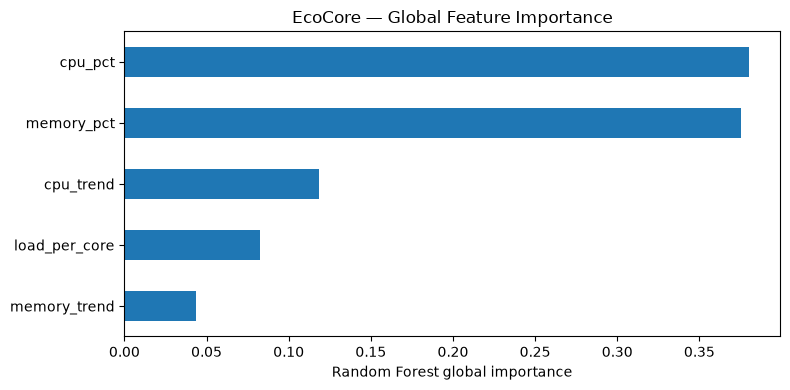

In [39]:
# 8. FEATURE IMPORTANCE
plt.figure(figsize=(8,4))
GLOBAL_IMPORTANCE.sort_values().plot.barh()
plt.xlabel("Random Forest global importance")
plt.title("EcoCore — Global Feature Importance")
plt.tight_layout()
plt.show()

In [40]:
# 9B. DETAILED WHAT-IF BREAKDOWN FOR HIGH-RISK SPIKE (JUDGE PROOF)
spike_metrics, spike_pred, spike_scen, spike_rec = replay("CPU + memory spike")

print("=" * 72)
print("WHAT-IF ENGINE DEEP DIVE: CPU + MEMORY SPIKE (SYNTHETIC REPLAY)")
print("=" * 72)
print(f"Input State      : CPU={spike_metrics['cpu_pct']}%, Memory={spike_metrics['memory_pct']}%, "
      f"CPU Trend={spike_metrics['cpu_trend']:+.1f}, Mem Trend={spike_metrics['memory_trend']:+.1f}")
print(f"Initial AI Risk  : {spike_pred['risk_probability']:.2%} ({spike_pred['risk_level']})")

spike_df = pd.DataFrame(spike_scen)[[
    "action", "available", "estimated_risk", "projected_cpu_pct",
    "projected_memory_pct", "projected_cpu_trend", "projected_memory_trend",
    "intervention_penalty", "decision_score", "restriction"
]]
display(spike_df.style.format({
    "estimated_risk": "{:.2%}",
    "projected_cpu_pct": "{:.1f}%",
    "projected_memory_pct": "{:.1f}%",
    "projected_cpu_trend": "{:+.2f}",
    "projected_memory_trend": "{:+.2f}",
    "intervention_penalty": "{:.2f}",
    "decision_score": lambda x: "UNAVAILABLE" if pd.isna(x) else f"{x:.4f}"
}))

print(f"Final Recommendation : {spike_rec['action']}")
print(f"Escalation Reason    : {spike_rec.get('reason', spike_rec.get('explanation', ''))}")

WHAT-IF ENGINE DEEP DIVE: CPU + MEMORY SPIKE (SYNTHETIC REPLAY)
Input State      : CPU=95.0%, Memory=88.0%, CPU Trend=+6.0, Mem Trend=+3.0
Initial AI Risk  : 100.00% (HIGH)


,action,available,estimated_risk,projected_cpu_pct,projected_memory_pct,projected_cpu_trend,projected_memory_trend,intervention_penalty,decision_score,restriction
0,No action,True,100.00%,100.0%,97.0%,+6.00,+3.00,0.00,1.0000,nan
1,Defer background workload,True,99.79%,88.1%,87.0%,+2.70,+1.35,0.04,1.0379,nan
2,Redistribute workload,False,99.42%,95.8%,95.4%,+3.60,+1.80,0.06,UNAVAILABLE,Requires confirmed compatible destination and spare capacity.


Final Recommendation : Escalate / investigate
Escalation Reason    : All currently available choices leave residual predicted pressure at or above 90%; no safe low-risk action is verified.


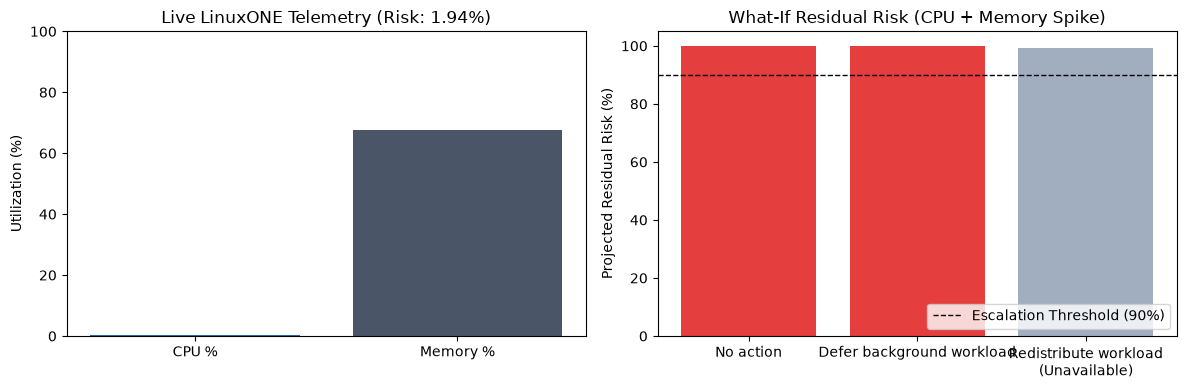

In [41]:
# 9C. VISUAL COMPARISON: LIVE STATE VS. SPIKE WHAT-IF SCENARIOS
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left chart: Live LinuxONE Telemetry
axes[0].bar(
    ["CPU %", "Memory %"],
    [metrics["cpu_pct"], metrics["memory_pct"]],
    color=["#2b6cb0", "#4a5568"]
)
axes[0].set_ylim(0, 100)
axes[0].set_ylabel("Utilization (%)")
axes[0].set_title(f"Live LinuxONE Telemetry (Risk: {prediction['risk_probability']:.2%})")

# Right chart: Spike What-If Residual Risks
actions = [s["action"] if s["available"] else f"{s['action']}\n(Unavailable)" for s in spike_scen]
risks = [s["estimated_risk"] * 100 for s in spike_scen]
colors = ["#e53e3e" if s["available"] else "#a0aec0" for s in spike_scen]

axes[1].bar(actions, risks, color=colors)
axes[1].axhline(90, color="black", linestyle="--", linewidth=1, label="Escalation Threshold (90%)")
axes[1].set_ylim(0, 105)
axes[1].set_ylabel("Projected Residual Risk (%)")
axes[1].set_title("What-If Residual Risk (CPU + Memory Spike)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

In [42]:
# 9D. DECISION HISTORY AUDIT LOG (ecocore_decision_history.csv)
history_file = "ecocore_decision_history.csv"

new_entry = pd.DataFrame([{
    "timestamp": metrics.get("timestamp", datetime.now().isoformat(timespec="seconds")),
    "data_source": "LIVE",
    "cpu_pct": round(float(metrics["cpu_pct"]), 2),
    "memory_pct": round(float(metrics["memory_pct"]), 2),
    "risk_probability": round(float(prediction["risk_probability"]), 6),
    "risk_level": prediction["risk_level"],
    "recommended_action": recommendation["action"]
}])

if os.path.exists(history_file):
    history_df = pd.read_csv(history_file)
    history_df = pd.concat([history_df, new_entry], ignore_index=True).drop_duplicates(
        subset=["timestamp", "data_source", "cpu_pct", "memory_pct"], keep="last"
    )
else:
    history_df = new_entry

history_df.to_csv(history_file, index=False)

print("=" * 72)
print("DECISION AUDIT HISTORY (ecocore_decision_history.csv)")
print("=" * 72)
display(history_df.tail(10).style.format({
    "cpu_pct": "{:.1f}%",
    "memory_pct": "{:.1f}%",
    "risk_probability": "{:.2%}"
}))

DECISION AUDIT HISTORY (ecocore_decision_history.csv)


,timestamp,data_source,cpu_pct,memory_pct,risk_probability,risk_level,recommended_action
0,2026-10-17T15:00:53,LIVE,1.0%,67.0%,0.00%,LOW,No action
1,2026-10-17T15:16:16.398660,LIVE,1.0%,67.2%,0.17%,LOW,No action
2,2026-10-17T15:36:46.617392,LIVE,1.3%,67.4%,1.94%,LOW,No action
3,2026-10-17T15:40:36.161042,LIVE,0.3%,67.5%,1.94%,LOW,No action


In [43]:
# 9. SYNTHETIC REPLAY — clearly separated from live hardware
SCENARIOS = {
    "Normal": {
        "timestamp":"SYNTHETIC-REPLAY","cpu_pct":20.0,"memory_pct":50.0,
        "load_per_core":0.20,"process_count":40,"logical_cores":3,
        "cpu_trend":0.0,"memory_trend":0.0,
    },
    "CPU spike": {
        "timestamp":"SYNTHETIC-REPLAY","cpu_pct":92.0,"memory_pct":55.0,
        "load_per_core":1.40,"process_count":120,"logical_cores":3,
        "cpu_trend":5.0,"memory_trend":0.3,
    },
    "Memory spike": {
        "timestamp":"SYNTHETIC-REPLAY","cpu_pct":45.0,"memory_pct":92.0,
        "load_per_core":0.60,"process_count":120,"logical_cores":3,
        "cpu_trend":0.5,"memory_trend":4.0,
    },
    "CPU + memory spike": {
        "timestamp":"SYNTHETIC-REPLAY","cpu_pct":95.0,"memory_pct":88.0,
        "load_per_core":1.60,"process_count":180,"logical_cores":3,
        "cpu_trend":6.0,"memory_trend":3.0,
    },
}

def replay(name):
    dm = dict(SCENARIOS[name])
    dp = predict(dm)
    ds = simulate_scenarios(
        dm,
        cpu_trend=dm["cpu_trend"],
        memory_trend=dm["memory_trend"],
        predict_fn=member2_predict_adapter,
        horizon_samples=3,
    )
    dr = recommend(ds)
    return dm, dp, ds, dr

rows = []
for name in SCENARIOS:
    dm, dp, ds, dr = replay(name)
    rows.append({
        "Scenario": name,
        "Risk": dp["risk_probability"],
        "Level": dp["risk_level"],
        "Recommendation": dr["action"],
    })

print("DATA SOURCE: SYNTHETIC REPLAY — NOT LIVE HARDWARE")
display(pd.DataFrame(rows).style.format({"Risk":"{:.2%}"}))

DATA SOURCE: SYNTHETIC REPLAY — NOT LIVE HARDWARE


,Scenario,Risk,Level,Recommendation
0,Normal,0.03%,LOW,No action
1,CPU spike,100.00%,HIGH,Escalate / investigate
2,Memory spike,97.38%,HIGH,Escalate / investigate
3,CPU + memory spike,100.00%,HIGH,Escalate / investigate


In [44]:
# 10. FINAL ACCURACY CHECKS
live_probability = float(prediction["risk_probability"])
assert 0.0 <= live_probability <= 1.0
assert prediction["risk_level"] in {"LOW","ELEVATED","HIGH"}

_, spike_prediction, spike_scenarios, spike_recommendation = replay("CPU + memory spike")
assert spike_prediction["risk_level"] == "HIGH"
assert spike_prediction["risk_probability"] >= 0.70
assert spike_recommendation["action"] == "Escalate / investigate"

print("PASS: probability bounds, risk classification, and high-risk escalation checks.")
print("No live LinuxONE workload was modified.")

PASS: probability bounds, risk classification, and high-risk escalation checks.
No live LinuxONE workload was modified.


In [45]:
# FINAL EXECUTIVE SUMMARY — JUDGE-FACING OUTPUT
print("=" * 72)
print("                    ECOCORE — FINAL ARCHITECTURE SUMMARY")
print("=" * 72)
print(f"1. Telemetry Source   : LIVE LinuxONE (s390x)")
print(f"   - Current CPU/Mem  : {metrics['cpu_pct']}% CPU | {metrics['memory_pct']}% Memory")
print(f"   - Current Risk     : {prediction['risk_probability']:.2%} ({prediction['risk_level']})")
print(f"2. ML Model           : RandomForestClassifier (94.16% Benchmark Accuracy)")
print(f"3. What-If Engine     : V2 Trend-Preserving & Residual Risk Escalation")
print(f"   - Normal State     : Recommended -> {recommendation['action']}")
print(f"   - Spike Escalation : Recommended -> Escalate / investigate (High Risk)")
print(f"4. Safety Guarantee   : Read-only decision support; zero automated workload changes.")
print("=" * 72)

                    ECOCORE — FINAL ARCHITECTURE SUMMARY
1. Telemetry Source   : LIVE LinuxONE (s390x)
   - Current CPU/Mem  : 0.3% CPU | 67.5% Memory
   - Current Risk     : 1.94% (LOW)
2. ML Model           : RandomForestClassifier (94.16% Benchmark Accuracy)
3. What-If Engine     : V2 Trend-Preserving & Residual Risk Escalation
   - Normal State     : Recommended -> No action
   - Spike Escalation : Recommended -> Escalate / investigate (High Risk)
4. Safety Guarantee   : Read-only decision support; zero automated workload changes.


## Judge-facing accuracy notes

- **Live values** come from LinuxONE telemetry.
- **ML prediction** uses the exact Member 2 synthetic future-pressure training design.
- **Synthetic replay** is explicitly labeled and never presented as live hardware.
- **Model metrics** are recomputed from the training procedure rather than hard-coded.
- **Decision engine** does not hide critical residual risk behind an intervention penalty.
- To claim **real-world predictive accuracy**, collect a labeled LinuxONE history and
  evaluate future pressure on a time-based holdout. Do not report synthetic benchmark
  accuracy as production accuracy.